# Forecasting & Replenishment Assignment

## Background

You are the data scientist supporting the owner of a small chain of two grocery
stores, **Riverside Grocery** and **Uptown Fresh Market**. Both stores carry
the same lineup of five exotic fruits, sourced from the same supplier at a
fixed per-unit cost, but sold at different prices at each store (so the
profit margin per unit differs by store).

Every week the stores report how many units of each fruit they sold. You have
been given ~2 years of this weekly sales history in `data.csv`.

The owner has one procurement budget of **$1,000** to spend (across both
stores combined) on stocking the two upcoming weeks, and wants to know
exactly how many units of each fruit to buy for each store.

## What you need to do

**Part 1 — Forecast.**
For each of the 5 products and 2 stores (10 series total), forecast weekly
units sold for the next two weeks: **2026-W29** and **2026-W30**. Use
whatever forecasting approach you think is appropriate.

**Part 2 — Optimize.**
Using your forecasts, formulate and solve an optimization problem that
decides how many units of each product to purchase for each store, in order
to:

- **Maximize total profit** across both stores, subject to:
  - The **total procurement budget** of $1,000 (shared across both stores) is
    not exceeded.
  - Each store must generate **at least its minimum required revenue** over
    the two-week horizon (see the facts table below).
  - Purchase quantities are **non-negative integers**.

## Deliverables

1. Your two-week forecast for each of the 10 product/store series (numbers
   and/or a plot), with a short explanation of your approach.
2. Your optimization model: clearly stated decision variables, objective
   function, and constraints.
3. The final recommended purchase quantities per product/store, the
   resulting total profit, and a few sentences on any assumptions or
   trade-offs you made.

You do not need to build anything beyond this notebook. Budget roughly
2-3 hours for the whole assignment — we are more interested in sound
reasoning and a working, correctly-formulated model than in a polished or
exhaustive solution.

## Known facts

| Fact | Value |
|---|---|
| Forecast horizon | 2 weeks: **2026-W29** and **2026-W30** |
| Historical data range (`data.csv`) | **2024-W20** to **2026-W28**, weekly |
| Stores | Riverside Grocery, Uptown Fresh Market |
| Products | Dragon Fruit, Passion Fruit, Lychee, Rambutan, Kiwano |
| Total procurement budget (shared across both stores, 2-week horizon) | **$1,000.00** |
| Min. required revenue — Riverside Grocery (2-week horizon) | **$500.00** |
| Min. required revenue — Uptown Fresh Market (2-week horizon) | **$520.00** |
| Purchase quantities | Non-negative **integers** |

**Product cost** (paid by the store per unit purchased, same at both stores):

| Product | Cost ($/unit) |
|---|---|
| Dragon Fruit | 2.20 |
| Passion Fruit | 1.50 |
| Lychee | 3.00 |
| Rambutan | 4.50 |
| Kiwano | 5.50 |

**Profit margin** ($/unit sold, differs by store — this is profit, i.e.
revenue already net of the cost above):

| Product | Riverside Grocery | Uptown Fresh Market |
|---|---|---|
| Dragon Fruit | 1.30 | 1.55 |
| Passion Fruit | 0.90 | 0.75 |
| Lychee | 1.75 | 1.40 |
| Rambutan | 2.60 | 3.10 |
| Kiwano | 3.20 | 2.70 |

*(Revenue per unit sold = cost + margin, i.e. the retail price.)*

## Setup

In [1]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from ipywidgets import interact, widgets

pd.options.display.float_format = "{:.2f}".format

# --- known facts, as data structures you can use directly in your model ---

STORES = ["Riverside Grocery", "Uptown Fresh Market"]
PRODUCTS = ["Dragon Fruit", "Passion Fruit", "Lychee", "Rambutan", "Kiwano"]

COST = {
    "Dragon Fruit": 2.20,
    "Passion Fruit": 1.50,
    "Lychee": 3.00,
    "Rambutan": 4.50,
    "Kiwano": 5.50,
}

MARGIN = {
    ("Dragon Fruit", "Riverside Grocery"): 1.30,
    ("Dragon Fruit", "Uptown Fresh Market"): 1.55,
    ("Passion Fruit", "Riverside Grocery"): 0.90,
    ("Passion Fruit", "Uptown Fresh Market"): 0.75,
    ("Lychee", "Riverside Grocery"): 1.75,
    ("Lychee", "Uptown Fresh Market"): 1.40,
    ("Rambutan", "Riverside Grocery"): 2.60,
    ("Rambutan", "Uptown Fresh Market"): 3.10,
    ("Kiwano", "Riverside Grocery"): 3.20,
    ("Kiwano", "Uptown Fresh Market"): 2.70,
}

BUDGET = 1000.00

MIN_REVENUE = {
    "Riverside Grocery": 500.00,
    "Uptown Fresh Market": 520.00,
}

FORECAST_WEEKS = ["2026-W29", "2026-W30"]

## Load & explore the data

In [3]:
df = pd.read_csv("data.csv", parse_dates=["week_start_date"])
df = df.sort_values(["product", "store", "week_start_date"]).reset_index(drop=True)
print(df.shape)
df.head()

(1130, 5)


,week,week_start_date,product,store,units_sold
0,2024-W20,2024-05-13,Dragon Fruit,Riverside Grocery,59
1,2024-W21,2024-05-20,Dragon Fruit,Riverside Grocery,52
2,2024-W22,2024-05-27,Dragon Fruit,Riverside Grocery,57
3,2024-W23,2024-06-03,Dragon Fruit,Riverside Grocery,46
4,2024-W24,2024-06-10,Dragon Fruit,Riverside Grocery,54


In [4]:
def plot_series(product, store):
    sub = df[(df["product"] == product) & (df["store"] == store)]
    fig = go.Figure()
    fig.add_trace(
        go.Scatter(
            x=sub["week_start_date"],
            y=sub["units_sold"],
            mode="lines+markers",
            name=f"{product} @ {store}",
        )
    )
    fig.update_layout(
        title=f"Weekly units sold — {product} @ {store}",
        xaxis_title="Week",
        yaxis_title="Units sold",
        height=450,
    )
    fig.show()


interact(
    plot_series,
    product=widgets.Dropdown(options=PRODUCTS, description="Product"),
    store=widgets.Dropdown(options=STORES, description="Store"),
);

interactive(children=(Dropdown(description='Product', options=('Dragon Fruit', 'Passion Fruit', 'Lychee', 'Ram…

## Your solution

Use the sections below (or restructure them however you like) to work
through Part 1 (forecasting) and Part 2 (optimization).

### Part 1 — Forecasting

Forecast `units_sold` for each product/store pair for 2026-W29 and 2026-W30.

In [6]:
# Part 1 
# 1. Data Quality Checks

print("Dataset shape:", df.shape)

print("\n--- Columns ---")
print(df.columns.tolist())

print("\n--- Missing values ---")
print(df.isnull().sum())

print("\n--- Duplicated rows ---")
print(df.duplicated().sum())

print("\n--- Products ---")
print(df["product"].unique())

print("\n--- Stores ---")
print(df["store"].unique())

print("\n--- Date range ---")
print(df["week_start_date"].min(), "to", df["week_start_date"].max())

print("\n--- Negative sales ---")
print((df["units_sold"] < 0).sum())

series_counts = (
    df.groupby(["product", "store"])["week_start_date"]
      .agg(["count", "min", "max"])
      .reset_index()
)

print(series_counts)
duplicates = df.duplicated(
    subset=["week_start_date", "product", "store"]
).sum()

print("Duplicated product-store-week combinations:", duplicates)

Dataset shape: (1130, 5)

--- Columns ---
['week', 'week_start_date', 'product', 'store', 'units_sold']

--- Missing values ---
week               0
week_start_date    0
product            0
store              0
units_sold         0
dtype: int64

--- Duplicated rows ---
0

--- Products ---
['Dragon Fruit' 'Kiwano' 'Lychee' 'Passion Fruit' 'Rambutan']

--- Stores ---
['Riverside Grocery' 'Uptown Fresh Market']

--- Date range ---
2024-05-13 00:00:00 to 2026-07-06 00:00:00

--- Negative sales ---
0
         product                store  count        min        max
0   Dragon Fruit    Riverside Grocery    113 2024-05-13 2026-07-06
1   Dragon Fruit  Uptown Fresh Market    113 2024-05-13 2026-07-06
2         Kiwano    Riverside Grocery    113 2024-05-13 2026-07-06
3         Kiwano  Uptown Fresh Market    113 2024-05-13 2026-07-06
4         Lychee    Riverside Grocery    113 2024-05-13 2026-07-06
5         Lychee  Uptown Fresh Market    113 2024-05-13 2026-07-06
6  Passion Fruit    Riverside

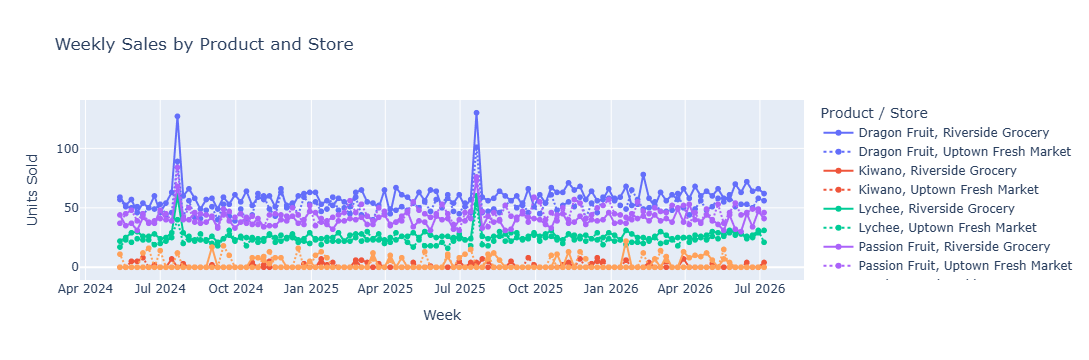

In [8]:

import plotly.express as px
# Create a line chart showing weekly sales for all products and stores
fig = px.line(
    df,
    x="week_start_date",   # X-axis: the week/date
    y="units_sold",       # Y-axis: number of units sold
    color="product",      # Use a different color for each product
    line_dash="store",    # Use different line styles for each store
    title="Weekly Sales by Product and Store",
    markers=True          # Display individual weekly observations
)

# Customize the axis labels and legend title
fig.update_layout(
    xaxis_title="Week",
    yaxis_title="Units Sold",
    legend_title="Product / Store"
)

# Display the interactive chart
fig.show()


In [9]:

# Calculate total units sold across all products and stores for each week
weekly_total = (
    df.groupby("week_start_date")["units_sold"]
      .sum()
      .reset_index()
)


# Display the 10 weeks with the highest total sales
print(
    weekly_total
    .sort_values("units_sold", ascending=False)
    .head(10)
)


    week_start_date  units_sold
62       2025-07-21         497
10       2024-07-22         480
80       2025-11-24         294
111      2026-06-29         280
85       2025-12-29         280
98       2026-03-30         276
78       2025-11-10         276
91       2026-02-09         274
75       2025-10-20         274
88       2026-01-19         274


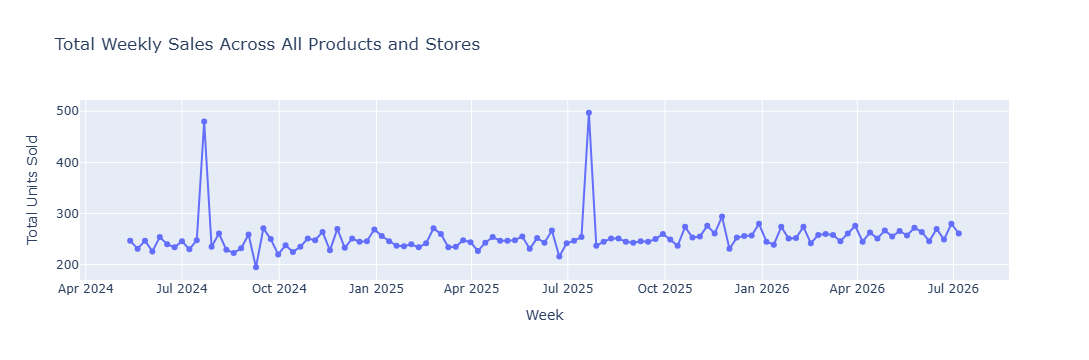

In [10]:

# Create a line chart showing total weekly sales across all products and stores
fig = px.line(
    weekly_total,
    x="week_start_date",   # X-axis: the week/date
    y="units_sold",       # Y-axis: total units sold that week
    title="Total Weekly Sales Across All Products and Stores",
    markers=True          # Display individual weekly observations
)


# Customize the axis labels
fig.update_layout(
    xaxis_title="Week",
    yaxis_title="Total Units Sold"
)


# Display the interactive chart
fig.show()

In [11]:
# 1.2 Annual seasonality
# The data shows evidence of a recurring annual demand pattern, particularly around July
# Check for annual seasonality using a 52-week lag

# Sort the data by product, store, and date
df_sorted = df.sort_values(
    ["product", "store", "week_start_date"]
).copy()

# Calculate sales from 52 weeks earlier for each product-store series
df_sorted["units_sold_lag_52"] = (
    df_sorted
    .groupby(["product", "store"])["units_sold"]
    .shift(52)
)

# Calculate the correlation between current sales and sales 52 weeks earlier
seasonality_check = (
    df_sorted
    .dropna(subset=["units_sold_lag_52"])
    .groupby(["product", "store"])
    .apply(
        lambda x: x["units_sold"].corr(x["units_sold_lag_52"]),
        include_groups=False
    )
    .reset_index(name="correlation_lag_52")
)

# Display the results
print(seasonality_check)

         product                store  correlation_lag_52
0   Dragon Fruit    Riverside Grocery                0.72
1   Dragon Fruit  Uptown Fresh Market                0.64
2         Kiwano    Riverside Grocery                0.10
3         Kiwano  Uptown Fresh Market                0.03
4         Lychee    Riverside Grocery                0.78
5         Lychee  Uptown Fresh Market                0.39
6  Passion Fruit    Riverside Grocery                0.46
7  Passion Fruit  Uptown Fresh Market                0.44
8       Rambutan    Riverside Grocery                0.00
9       Rambutan  Uptown Fresh Market               -0.02


In [13]:
# 1.3 Recent trend
# Check recent demand trends for each product-store series

import numpy as np


# Sort the data chronologically within each product-store series
df_sorted = df.sort_values(
    ["product", "store", "week_start_date"]
).copy()


# Calculate the overall historical average for each series
historical_avg = (
    df_sorted
    .groupby(["product", "store"])["units_sold"]
    .mean()
    .rename("historical_avg")
)


# Calculate the average sales over the most recent 26 weeks
recent_avg = (
    df_sorted
    .groupby(["product", "store"])
    .tail(26)
    .groupby(["product", "store"])["units_sold"]
    .mean()
    .rename("recent_26w_avg")
)


# Combine the historical and recent averages
trend_summary = pd.concat(
    [historical_avg, recent_avg],
    axis=1
).reset_index()


# Calculate the percentage change from the historical average
# to the recent 26-week average
trend_summary["recent_change_pct"] = (
    (trend_summary["recent_26w_avg"] -
     trend_summary["historical_avg"])
    / trend_summary["historical_avg"]
    * 100
)


# Calculate a linear trend slope for each product-store series
def calculate_slope(group):
    y = group["units_sold"].values
    x = np.arange(len(y))
    return np.polyfit(x, y, 1)[0]


slopes = (
    df_sorted
    .groupby(["product", "store"])
    .apply(calculate_slope, include_groups=False)
    .rename("trend_slope")
)


# Add the slopes to the summary table
trend_summary = trend_summary.merge(
    slopes.reset_index(),
    on=["product", "store"]
)


# Display the results
trend_summary = trend_summary.sort_values(
    ["product", "store"]
)

print(trend_summary.round(2))

         product                store  historical_avg  recent_26w_avg  \
0   Dragon Fruit    Riverside Grocery           60.03           61.92   
1   Dragon Fruit  Uptown Fresh Market           51.54           52.85   
2         Kiwano    Riverside Grocery            0.73            0.58   
3         Kiwano  Uptown Fresh Market            1.04            0.69   
4         Lychee    Riverside Grocery           26.34           26.77   
5         Lychee  Uptown Fresh Market           23.56           23.92   
6  Passion Fruit    Riverside Grocery           40.01           40.27   
7  Passion Fruit  Uptown Fresh Market           45.13           46.19   
8       Rambutan    Riverside Grocery            2.28            4.12   
9       Rambutan  Uptown Fresh Market            2.84            1.81   

   recent_change_pct  trend_slope  
0               3.16         0.05  
1               2.53         0.04  
2             -20.50         0.00  
3             -33.70        -0.00  
4               

In [16]:
# 1.4 Forecasting Models  Creation and Comparison
# Temporal Validation

# Number of weeks to forecast at each validation step
FORECAST_HORIZON = 2

# Number of validation windows
N_WINDOWS = 6


# Create rolling two-week validation windows
def create_validation_windows(series, horizon=2, n_windows=6):
    """
    Create rolling train/test windows for time-series validation.

    Each test set contains the next `horizon` weeks,
    while the training set contains all observations before it.
    """
    
    n = len(series)
    windows = []

    # Start from the end of the series and move backward
    for i in range(n_windows):
        test_end = n - i * horizon
        test_start = test_end - horizon

        train = series.iloc[:test_start]
        test = series.iloc[test_start:test_end]

        windows.append((train, test))

    # Return windows in chronological order
    return windows[::-1]


# Example using one product-store series
example_series = (
    df_sorted[
        (df_sorted["product"] == "Dragon Fruit") &
        (df_sorted["store"] == "Riverside Grocery")
    ]
    .sort_values("week_start_date")["units_sold"]
    .reset_index(drop=True)
)


# Create the validation windows
example_windows = create_validation_windows(
    example_series,
    horizon=FORECAST_HORIZON,
    n_windows=N_WINDOWS
)


# Display the size of each training and validation period
for i, (train, test) in enumerate(example_windows, start=1):
    print(
        f"Window {i}: "
        f"Train = {len(train)} weeks, "
        f"Validation = {len(test)} weeks"
    )

Window 1: Train = 101 weeks, Validation = 2 weeks
Window 2: Train = 103 weeks, Validation = 2 weeks
Window 3: Train = 105 weeks, Validation = 2 weeks
Window 4: Train = 107 weeks, Validation = 2 weeks
Window 5: Train = 109 weeks, Validation = 2 weeks
Window 6: Train = 111 weeks, Validation = 2 weeks


In [17]:
# Naive Baseline

from sklearn.metrics import mean_absolute_error, mean_squared_error


# Generate naive forecasts for each validation window
def naive_forecast(train, horizon=2):
    """
    Forecast the next observations using the last observed value.
    """
    last_value = train.iloc[-1]
    return np.repeat(last_value, horizon)


# Store validation results
naive_results = []


# Evaluate the Naive model for every product-store series
for (product, store), group in df_sorted.groupby(["product", "store"]):

    series = (
        group
        .sort_values("week_start_date")["units_sold"]
        .reset_index(drop=True)
    )

    windows = create_validation_windows(
        series,
        horizon=FORECAST_HORIZON,
        n_windows=N_WINDOWS
    )

    # Evaluate each validation window
    for window_id, (train, test) in enumerate(windows, start=1):

        # Generate the two-week forecast
        forecast = naive_forecast(
            train,
            horizon=FORECAST_HORIZON
        )

        # Calculate validation metrics
        mae = mean_absolute_error(test, forecast)
        rmse = np.sqrt(mean_squared_error(test, forecast))

        naive_results.append({
            "product": product,
            "store": store,
            "window": window_id,
            "MAE": mae,
            "RMSE": rmse
        })


# Convert results to a DataFrame
naive_results = pd.DataFrame(naive_results)


# Calculate average performance across validation windows
naive_summary = (
    naive_results
    .groupby(["product", "store"])[["MAE", "RMSE"]]
    .mean()
    .reset_index()
)


# Display the results
print("Naive model performance by product and store:")
print(naive_summary.round(2))

Naive model performance by product and store:
         product                store  MAE  RMSE
0   Dragon Fruit    Riverside Grocery 5.67  6.09
1   Dragon Fruit  Uptown Fresh Market 5.17  5.61
2         Kiwano    Riverside Grocery 0.33  0.47
3         Kiwano  Uptown Fresh Market 0.58  0.82
4         Lychee    Riverside Grocery 2.75  2.86
5         Lychee  Uptown Fresh Market 2.83  3.09
6  Passion Fruit    Riverside Grocery 8.00  8.44
7  Passion Fruit  Uptown Fresh Market 5.75  6.41
8       Rambutan    Riverside Grocery 3.33  3.46
9       Rambutan  Uptown Fresh Market 1.25  1.77


In [18]:
# Moving Average

# Candidate window sizes for the moving average
MA_WINDOWS = [4, 8, 12]


# Generate a moving-average forecast
def moving_average_forecast(train, horizon=2, window=4):
    """
    Forecast future observations using the average
    of the most recent observations.
    """
    
    # Calculate the average of the most recent observations
    average = train.iloc[-window:].mean()

    # Use the same average for all forecasted weeks
    return np.repeat(average, horizon)


# Store all Moving Average validation results
moving_average_results = []


# Evaluate each window size
for ma_window in MA_WINDOWS:

    # Evaluate every product-store series
    for (product, store), group in df_sorted.groupby(["product", "store"]):

        series = (
            group
            .sort_values("week_start_date")["units_sold"]
            .reset_index(drop=True)
        )

        windows = create_validation_windows(
            series,
            horizon=FORECAST_HORIZON,
            n_windows=N_WINDOWS
        )

        # Evaluate each validation window
        for window_id, (train, test) in enumerate(windows, start=1):

            # Generate the two-week forecast
            forecast = moving_average_forecast(
                train,
                horizon=FORECAST_HORIZON,
                window=ma_window
            )

            # Calculate validation metrics
            mae = mean_absolute_error(test, forecast)
            rmse = np.sqrt(mean_squared_error(test, forecast))

            moving_average_results.append({
                "window_size": ma_window,
                "product": product,
                "store": store,
                "validation_window": window_id,
                "MAE": mae,
                "RMSE": rmse
            })


# Convert results to a DataFrame
moving_average_results = pd.DataFrame(
    moving_average_results
)


# Average performance across validation windows
moving_average_summary = (
    moving_average_results
    .groupby(
        ["window_size", "product", "store"]
    )[["MAE", "RMSE"]]
    .mean()
    .reset_index()
)


# Display the results
print(
    moving_average_summary
    .round(2)
    .to_string(index=False)
)

 window_size       product               store  MAE  RMSE
           4  Dragon Fruit   Riverside Grocery 4.25  4.71
           4  Dragon Fruit Uptown Fresh Market 4.50  4.92
           4        Kiwano   Riverside Grocery 0.62  0.76
           4        Kiwano Uptown Fresh Market 1.00  1.24
           4        Lychee   Riverside Grocery 2.54  2.74
           4        Lychee Uptown Fresh Market 2.29  2.59
           4 Passion Fruit   Riverside Grocery 6.21  6.93
           4 Passion Fruit Uptown Fresh Market 4.42  5.30
           4      Rambutan   Riverside Grocery 3.00  3.25
           4      Rambutan Uptown Fresh Market 2.50  3.02
           8  Dragon Fruit   Riverside Grocery 3.79  4.40
           8  Dragon Fruit Uptown Fresh Market 3.40  3.93
           8        Kiwano   Riverside Grocery 0.77  0.91
           8        Kiwano Uptown Fresh Market 0.96  1.09
           8        Lychee   Riverside Grocery 2.54  2.73
           8        Lychee Uptown Fresh Market 2.69  2.90
           8 P

In [19]:
# Seasonal Naive Forecasting

# Seasonal period for weekly data with annual seasonality
SEASONAL_PERIOD = 52


# Generate a seasonal naive forecast
def seasonal_naive_forecast(train, horizon=2, seasonal_period=52):
    """
    Forecast future observations using the values
    from the same seasonal period in the previous year.
    """

    # Get the most recent seasonal observations
    seasonal_values = train.iloc[-seasonal_period:]

    # Repeat the seasonal pattern for the forecast horizon
    forecast = seasonal_values.iloc[:horizon].values

    return forecast


# Store Seasonal Naive validation results
seasonal_naive_results = []


# Evaluate each product-store series
for (product, store), group in df_sorted.groupby(["product", "store"]):

    series = (
        group
        .sort_values("week_start_date")["units_sold"]
        .reset_index(drop=True)
    )

    windows = create_validation_windows(
        series,
        horizon=FORECAST_HORIZON,
        n_windows=N_WINDOWS
    )

    # Evaluate each validation window
    for window_id, (train, test) in enumerate(windows, start=1):

        # Generate the two-week seasonal forecast
        forecast = seasonal_naive_forecast(
            train,
            horizon=FORECAST_HORIZON,
            seasonal_period=SEASONAL_PERIOD
        )

        # Calculate validation metrics
        mae = mean_absolute_error(test, forecast)
        rmse = np.sqrt(mean_squared_error(test, forecast))

        seasonal_naive_results.append({
            "product": product,
            "store": store,
            "validation_window": window_id,
            "MAE": mae,
            "RMSE": rmse
        })


# Convert results to a DataFrame
seasonal_naive_results = pd.DataFrame(
    seasonal_naive_results
)


# Average performance across validation windows
seasonal_naive_summary = (
    seasonal_naive_results
    .groupby(["product", "store"])[["MAE", "RMSE"]]
    .mean()
    .reset_index()
)


# Display the results
print(
    seasonal_naive_summary
    .round(2)
    .to_string(index=False)
)

      product               store  MAE  RMSE
 Dragon Fruit   Riverside Grocery 7.00  7.50
 Dragon Fruit Uptown Fresh Market 5.17  6.51
       Kiwano   Riverside Grocery 0.75  0.75
       Kiwano Uptown Fresh Market 0.50  0.71
       Lychee   Riverside Grocery 2.67  3.12
       Lychee Uptown Fresh Market 5.50  6.08
Passion Fruit   Riverside Grocery 6.08  6.35
Passion Fruit Uptown Fresh Market 7.33  8.61
     Rambutan   Riverside Grocery 3.25  4.14
     Rambutan Uptown Fresh Market 2.67  3.14


In [20]:
# Correlation with the previous year's values does not automatically mean that a seasonal forecasting model will produce better forecasts.
# Holt Exponential Smoothing

from statsmodels.tsa.holtwinters import ExponentialSmoothing


# Generate a two-week forecast using Holt's method
def holt_forecast(train, horizon=2):
    """
    Forecast future observations using exponential smoothing
    with a linear trend and no seasonal component.
    """

    # Fit the Holt exponential smoothing model
    model = ExponentialSmoothing(
        train,
        trend="add",
        seasonal=None,
        initialization_method="estimated"
    )

    # Fit the model to the training data
    fitted_model = model.fit(optimized=True)

    # Generate the forecast
    forecast = fitted_model.forecast(horizon)

    return np.asarray(forecast)


# Store Holt validation results
holt_results = []


# Evaluate each product-store series
for (product, store), group in df_sorted.groupby(["product", "store"]):

    series = (
        group
        .sort_values("week_start_date")["units_sold"]
        .reset_index(drop=True)
    )

    windows = create_validation_windows(
        series,
        horizon=FORECAST_HORIZON,
        n_windows=N_WINDOWS
    )

    # Evaluate each validation window
    for window_id, (train, test) in enumerate(windows, start=1):

        # Generate the two-week forecast
        forecast = holt_forecast(
            train,
            horizon=FORECAST_HORIZON
        )

        # Calculate validation metrics
        mae = mean_absolute_error(test, forecast)
        rmse = np.sqrt(mean_squared_error(test, forecast))

        holt_results.append({
            "product": product,
            "store": store,
            "validation_window": window_id,
            "MAE": mae,
            "RMSE": rmse
        })


# Convert results to a DataFrame
holt_results = pd.DataFrame(holt_results)


# Average performance across validation windows
holt_summary = (
    holt_results
    .groupby(["product", "store"])[["MAE", "RMSE"]]
    .mean()
    .reset_index()
)


# Display the results
print(
    holt_summary
    .round(2)
    .to_string(index=False)
)

      product               store  MAE  RMSE
 Dragon Fruit   Riverside Grocery 3.67  4.17
 Dragon Fruit Uptown Fresh Market 3.25  3.63
       Kiwano   Riverside Grocery 1.16  1.22
       Kiwano Uptown Fresh Market 1.22  1.29
       Lychee   Riverside Grocery 2.55  2.68
       Lychee Uptown Fresh Market 2.83  3.13
Passion Fruit   Riverside Grocery 5.27  5.67
Passion Fruit Uptown Fresh Market 4.47  5.07
     Rambutan   Riverside Grocery 3.95  4.10
     Rambutan Uptown Fresh Market 2.53  2.90


In [21]:
# Model Comparison
# Select the best Moving Average window for each product-store series
best_ma = (
    moving_average_summary
    .sort_values(
        ["product", "store", "MAE"]
    )
    .groupby(["product", "store"])
    .first()
    .reset_index()
)
# Rename the Moving Average columns for clarity
best_ma = best_ma.rename(
    columns={
        "window_size": "best_ma_window",
        "MAE": "MA_MAE",
        "RMSE": "MA_RMSE"
    }
)
# Rename metrics from the other models
naive_comparison = naive_summary.rename(
    columns={
        "MAE": "Naive_MAE",
        "RMSE": "Naive_RMSE"
    }
)
seasonal_comparison = seasonal_naive_summary.rename(
    columns={
        "MAE": "SeasonalNaive_MAE",
        "RMSE": "SeasonalNaive_RMSE"
    }
)
holt_comparison = holt_summary.rename(
    columns={
        "MAE": "Holt_MAE",
        "RMSE": "Holt_RMSE"
    }
)
# Combine all model results into one comparison table
model_comparison = (
    naive_comparison
    .merge(
        best_ma[
            [
                "product",
                "store",
                "best_ma_window",
                "MA_MAE",
                "MA_RMSE"
            ]
        ],
        on=["product", "store"]
    )
    .merge(
        seasonal_comparison,
        on=["product", "store"]
    )
    .merge(
        holt_comparison,
        on=["product", "store"]
    )
)
# Identify the model with the lowest MAE for each series
def select_best_model(row):

    model_errors = {
        "Naive": row["Naive_MAE"],
        "Moving Average": row["MA_MAE"],
        "Seasonal Naive": row["SeasonalNaive_MAE"],
        "Holt": row["Holt_MAE"]
    }

    return min(
        model_errors,
        key=model_errors.get
    )
model_comparison["Best_Model"] = model_comparison.apply(
    select_best_model,
    axis=1
)
# Display the complete comparison
print(
    model_comparison
    .round(2)
    .to_string(index=False)
)

      product               store  Naive_MAE  Naive_RMSE  best_ma_window  MA_MAE  MA_RMSE  SeasonalNaive_MAE  SeasonalNaive_RMSE  Holt_MAE  Holt_RMSE     Best_Model
 Dragon Fruit   Riverside Grocery       5.67        6.09              12    3.61     4.19               7.00                7.50      3.67       4.17 Moving Average
 Dragon Fruit Uptown Fresh Market       5.17        5.61               8    3.40     3.93               5.17                6.51      3.25       3.63           Holt
       Kiwano   Riverside Grocery       0.33        0.47               4    0.62     0.76               0.75                0.75      1.16       1.22          Naive
       Kiwano Uptown Fresh Market       0.58        0.82               8    0.96     1.09               0.50                0.71      1.22       1.29 Seasonal Naive
       Lychee   Riverside Grocery       2.75        2.86               4    2.54     2.74               2.67                3.12      2.55       2.68 Moving Average
       Lyc

In [22]:
#The product-store series exhibit different demand dynamics, so the best forecasting approach varies by series
# 1.5 Final Forecasting
# Store the final forecasts for all product-store series
final_forecasts = []

# Loop through each product-store series
for _, row in model_comparison.iterrows():

    product = row["product"]
    store = row["store"]
    best_model = row["Best_Model"]
    # Get the complete historical series
    series = (
        df_sorted[
            (df_sorted["product"] == product) &
            (df_sorted["store"] == store)
        ]
        .sort_values("week_start_date")["units_sold"]
        .reset_index(drop=True)
    )
    # Generate the forecast using the selected model
    if best_model == "Naive":

        forecast = naive_forecast(
            series,
            horizon=FORECAST_HORIZON
        )

        model_description = "Naive"

    elif best_model == "Moving Average":
        # Retrieve the best moving-average window
        ma_window = int(row["best_ma_window"])

        forecast = moving_average_forecast(
            series,
            horizon=FORECAST_HORIZON,
            window=ma_window
        )

        model_description = f"Moving Average ({ma_window} weeks)"

    elif best_model == "Seasonal Naive":

        forecast = seasonal_naive_forecast(
            series,
            horizon=FORECAST_HORIZON,
            seasonal_period=SEASONAL_PERIOD
        )

        model_description = "Seasonal Naive (52 weeks)"

    elif best_model == "Holt":

        forecast = holt_forecast(
            series,
            horizon=FORECAST_HORIZON
        )

        model_description = "Holt"
    # Store the two forecasted weeks
    final_forecasts.append({
        "product": product,
        "store": store,
        "model": model_description,
        "2026-W29": forecast[0],
        "2026-W30": forecast[1]
    })
# Convert forecasts into a DataFrame
final_forecasts = pd.DataFrame(final_forecasts)

# Round forecasts for presentation
final_forecasts["2026-W29"] = final_forecasts["2026-W29"].round(2)
final_forecasts["2026-W30"] = final_forecasts["2026-W30"].round(2)

# Display the final forecasts
print(
    final_forecasts.to_string(index=False)
)

      product               store                     model  2026-W29  2026-W30
 Dragon Fruit   Riverside Grocery Moving Average (12 weeks)     63.50     63.50
 Dragon Fruit Uptown Fresh Market                      Holt     53.65     53.69
       Kiwano   Riverside Grocery                     Naive      4.00      4.00
       Kiwano Uptown Fresh Market Seasonal Naive (52 weeks)      2.00      4.00
       Lychee   Riverside Grocery  Moving Average (4 weeks)     27.75     27.75
       Lychee Uptown Fresh Market  Moving Average (4 weeks)     25.75     25.75
Passion Fruit   Riverside Grocery                      Holt     40.08     40.08
Passion Fruit Uptown Fresh Market  Moving Average (4 weeks)     47.50     47.50
     Rambutan   Riverside Grocery  Moving Average (4 weeks)      0.00      0.00
     Rambutan Uptown Fresh Market                     Naive      0.00      0.00


In [24]:
# Forecasting approach and model selection
# I first examined the historical series for data quality, annual seasonality,
# and recent demand trends. The lag-52 analysis showed evidence of annual
# seasonality for some product-store series, particularly Dragon Fruit and
# Lychee Riverside.
# However, the presence of annual correlation was not treated as sufficient
# evidence to select a seasonal forecasting model. Seasonal Naive was evaluated
# alongside the other forecasting approaches using the same rolling two-week
# temporal validation framework.
# I evaluated four forecasting approaches: Naive, Moving Average, Seasonal Naive,
# and Holt's exponential smoothing with an additive trend and no seasonal
# component.
# The best-performing approach was selected independently for each product-store
# series based on validation MAE. This allowed the model choice to reflect the
# different demand dynamics observed across products and stores rather than
# imposing a single forecasting method on all series.
# Holt's method was used as a non-seasonal exponential smoothing alternative
# because the available history was limited to approximately two annual cycles,
# making a seasonal Holt-Winters specification less suitable for consistent
# evaluation across the validation windows.
# The selected models were then refit using the full 113-week history to
# generate forecasts for 2026-W29 and 2026-W30.

### Part 2 — Optimization and Allocation

In [25]:
# Part 2  Optimization and Allocation
# The final two-week forecasts are used as expected demand inputs
# for an inventory allocation optimization problem.

# The objective is to maximize total expected profit across both stores
# while satisfying the shared procurement budget, minimum revenue
# requirements for each store, forecasted demand limits, and integer
# purchase constraints.

# Prepare optimization inputs
# Calculate the expected two-week demand from the final forecasts
optimization_data = final_forecasts.copy()

optimization_data["forecast_demand"] = (
    optimization_data["2026-W29"] +
    optimization_data["2026-W30"]
)
# Unit procurement costs
product_costs = {
    "Dragon Fruit": 2.20,
    "Passion Fruit": 1.50,
    "Lychee": 3.00,
    "Rambutan": 4.50,
    "Kiwano": 5.50
}
# Profit margin per unit by store
profit_margins = {
    "Riverside Grocery": {
        "Dragon Fruit": 1.30,
        "Passion Fruit": 0.90,
        "Lychee": 1.75,
        "Rambutan": 2.60,
        "Kiwano": 3.20
    },
    "Uptown Fresh Market": {
        "Dragon Fruit": 1.55,
        "Passion Fruit": 0.75,
        "Lychee": 1.40,
        "Rambutan": 3.10,
        "Kiwano": 2.70
    }
}
# Add unit procurement cost
optimization_data["unit_cost"] = (
    optimization_data["product"]
    .map(product_costs)
)
# Add profit margin
optimization_data["profit_margin"] = (
    optimization_data.apply(
        lambda row: profit_margins[
            row["store"]
        ][row["product"]],
        axis=1
    )
)
# Calculate selling price
optimization_data["selling_price"] = (
    optimization_data["unit_cost"] +
    optimization_data["profit_margin"]
)
# Display the optimization inputs
print(
    optimization_data[
        [
            "product",
            "store",
            "2026-W29",
            "2026-W30",
            "forecast_demand",
            "unit_cost",
            "selling_price",
            "profit_margin"
        ]
    ].round(2).to_string(index=False)
)

      product               store  2026-W29  2026-W30  forecast_demand  unit_cost  selling_price  profit_margin
 Dragon Fruit   Riverside Grocery     63.50     63.50           127.00       2.20           3.50           1.30
 Dragon Fruit Uptown Fresh Market     53.65     53.69           107.34       2.20           3.75           1.55
       Kiwano   Riverside Grocery      4.00      4.00             8.00       5.50           8.70           3.20
       Kiwano Uptown Fresh Market      2.00      4.00             6.00       5.50           8.20           2.70
       Lychee   Riverside Grocery     27.75     27.75            55.50       3.00           4.75           1.75
       Lychee Uptown Fresh Market     25.75     25.75            51.50       3.00           4.40           1.40
Passion Fruit   Riverside Grocery     40.08     40.08            80.16       1.50           2.40           0.90
Passion Fruit Uptown Fresh Market     47.50     47.50            95.00       1.50           2.25        

In [27]:
# Rules 2.1

# Decision Variables
# For each product-store combination, the decision variable represents
# the number of units purchased for the two-week replenishment horizon.
# There are 10 decision variables: 5 products across 2 stores.
# All purchase quantities must be non-negative integers.

# 1O bjective Function
# The objective is to maximize total expected profit across both stores.
# Since the facts table provides profit per unit sold, the objective
# is calculated as the sum of purchased units multiplied by the
# corresponding profit margin.

# Optimization constraints
# The optimization is subject to four main requirements:
# 1. The total procurement cost across both stores cannot exceed $1,000.
# 2. Riverside Grocery must generate at least $500 in revenue.
# 3. Uptown Fresh Market must generate at least $520 in revenue.
# 4. Purchase quantities cannot exceed the forecasted two-week demand.
# All purchase quantities must also be non-negative integers.
    
from scipy.optimize import milp, LinearConstraint, Bounds
# Create a consistent list of product-store combinations
optimization_data = optimization_data.reset_index(drop=True)

n_variables = len(optimization_data)


# Coefficients for each decision variable
cost_coefficients = optimization_data["unit_cost"].values
profit_coefficients = optimization_data["profit_margin"].values
revenue_coefficients = optimization_data["selling_price"].values

# Maximum purchase quantity based on forecasted demand
demand_upper_bounds = optimization_data["forecast_demand"].values


# Constraint 1: Shared procurement budget

budget_constraint = LinearConstraint(
    cost_coefficients,
    -np.inf,
    1000
)


# Constraint 2: Minimum revenue by store

# Riverside revenue coefficients
riverside_mask = (
    optimization_data["store"] == "Riverside Grocery"
)

riverside_revenue = np.where(
    riverside_mask,
    revenue_coefficients,
    0
)


# Uptown revenue coefficients
uptown_mask = (
    optimization_data["store"] == "Uptown Fresh Market"
)

uptown_revenue = np.where(
    uptown_mask,
    revenue_coefficients,
    0
)


# Riverside must generate at least $500
riverside_constraint = LinearConstraint(
    riverside_revenue,
    500,
    np.inf
)


# Uptown must generate at least $520
uptown_constraint = LinearConstraint(
    uptown_revenue,
    520,
    np.inf
)


# Combine all constraints
constraints = [
    budget_constraint,
    riverside_constraint,
    uptown_constraint
]


# Variable bounds

# Lower bound = 0
# Upper bound = forecasted two-week demand
bounds = Bounds(
    np.zeros(n_variables),
    demand_upper_bounds
)


# Integer decision variables

integrality = np.ones(n_variables)


print(f"Number of decision variables: {n_variables}")
print("All purchase quantities are non-negative integers.")
print("Purchase quantities are capped by forecasted two-week demand.")

Number of decision variables: 10
All purchase quantities are non-negative integers.
Purchase quantities are capped by forecasted two-week demand.


In [28]:
# 2.2 Solve the Optimization

# The scipy.milp function minimizes by default.
# Therefore, we use the negative profit coefficients
# to maximize total expected profit.

objective = -profit_coefficients


# Solve the mixed-integer linear optimization problem
result = milp(
    c=objective,
    integrality=integrality,
    bounds=bounds,
    constraints=constraints
)


# Check solver status
print("Solver status:", result.message)


# Check whether an optimal solution was found
if result.success:

    print("Optimal solution found.")
    print(f"Optimal expected profit: ${-result.fun:.2f}")

else:

    print("The optimization did not find an optimal solution.")

Solver status: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Optimal solution found.
Optimal expected profit: $602.65


In [29]:
# 2.3 Recommended Purchase Quantities

# Create a results table from the optimal solution
optimization_results = optimization_data.copy()

# Add the optimal purchase quantities
optimization_results["purchase_quantity"] = np.rint(result.x).astype(int)

# Calculate expected revenue, procurement cost, and profit
optimization_results["expected_revenue"] = (
    optimization_results["purchase_quantity"]
    * optimization_results["selling_price"]
)

optimization_results["procurement_cost"] = (
    optimization_results["purchase_quantity"]
    * optimization_results["unit_cost"]
)

optimization_results["expected_profit"] = (
    optimization_results["purchase_quantity"]
    * optimization_results["profit_margin"]
)


# Display the recommended purchases
print(
    optimization_results[
        [
            "product",
            "store",
            "forecast_demand",
            "purchase_quantity",
            "unit_cost",
            "selling_price",
            "expected_revenue",
            "procurement_cost",
            "expected_profit"
        ]
    ].round(2).to_string(index=False)
)

      product               store  forecast_demand  purchase_quantity  unit_cost  selling_price  expected_revenue  procurement_cost  expected_profit
 Dragon Fruit   Riverside Grocery           127.00                127       2.20           3.50            444.50            279.40           165.10
 Dragon Fruit Uptown Fresh Market           107.34                107       2.20           3.75            401.25            235.40           165.85
       Kiwano   Riverside Grocery             8.00                  8       5.50           8.70             69.60             44.00            25.60
       Kiwano Uptown Fresh Market             6.00                  3       5.50           8.20             24.60             16.50             8.10
       Lychee   Riverside Grocery            55.50                 55       3.00           4.75            261.25            165.00            96.25
       Lychee Uptown Fresh Market            51.50                  0       3.00           4.40           

In [32]:
# 2.4 Constraint Verification

# Total procurement cost
total_cost = optimization_results["procurement_cost"].sum()

# Total expected profit
total_profit = optimization_results["expected_profit"].sum()

# Revenue by store
riverside_revenue = optimization_results.loc[
    optimization_results["store"] == "Riverside Grocery",
    "expected_revenue"
].sum()

uptown_revenue = optimization_results.loc[
    optimization_results["store"] == "Uptown Fresh Market",
    "expected_revenue"
].sum()

# Check all constraints
budget_ok = total_cost <= 1000
riverside_ok = riverside_revenue >= 500
uptown_ok = uptown_revenue >= 520
demand_ok = (
    optimization_results["purchase_quantity"]
    <= optimization_results["forecast_demand"] + 1e-9
).all()
integer_ok = (
    optimization_results["purchase_quantity"]
    == optimization_results["purchase_quantity"].astype(int)
).all()


# Display verification results
print(f"Total procurement cost: ${total_cost:.2f}")
print(f"Total expected profit: ${total_profit:.2f}")
print(f"Riverside expected revenue: ${riverside_revenue:.2f}")
print(f"Uptown expected revenue: ${uptown_revenue:.2f}")

print("\nConstraint checks:")
print(f"Budget <= $1,000: {budget_ok}")
print(f"Riverside revenue >= $500: {riverside_ok}")
print(f"Uptown revenue >= $520: {uptown_ok}")
print(f"Purchases <= forecast demand: {demand_ok}")
print(f"Purchase quantities are integers: {integer_ok}")
# How the optimization determines the allocation

#The optimization model does not independently decide how much to purchase for
#each product. Instead, it evaluates the 10 purchase decisions simultaneously.

#The objective function tells the solver to maximize total expected profit, while
#the constraints limit the feasible solutions by enforcing the shared $1,000
#budget, the minimum revenue requirements for both stores, the forecasted demand
#limits, and the integer purchase requirement.

#Therefore, the solver automatically determines how the limited budget should be
#distributed across products and stores. We do not manually prioritize products
#or assign a fixed amount of the budget to each store.

#For example, the model does not explicitly contain a rule saying that Passion
#Fruit at Uptown should be purchased at 93 units. Rather, 93 is the result of the
#overall optimization: given all 10 purchase decisions and all constraints, this
#combination produces the highest expected total profit.

Total procurement cost: $999.80
Total expected profit: $602.65
Riverside expected revenue: $967.35
Uptown expected revenue: $635.10

Constraint checks:
Budget <= $1,000: True
Riverside revenue >= $500: True
Uptown revenue >= $520: True
Purchases <= forecast demand: True
Purchase quantities are integers: True


### Part 3 — Recommendation

Summarize the recommended purchase quantities, total profit, and any assumptions or trade-offs.

In [33]:
## Part 3  Recommendation

# I used the forecasting and optimization analysis to decide how the available
# $1,000 procurement budget should be spent across Riverside Grocery and Uptown
# Fresh Market for the next two weeks.

# First, I estimated how many units of each fruit each store is likely to sell
# during 2026-W29 and 2026-W30. I tested four forecasting approaches using
# rolling two-week temporal validation: Naive, Moving Average, Seasonal Naive,
# and Holt's exponential smoothing. Instead of assuming that one model would work
# best for every product, I selected the model that performed best for each
# product-store combination based on validation MAE. The selected models were
# then refit using the full 113-week history to generate the final forecasts.

# I then used these forecasts to guide the purchasing decision. The goal was not
# simply to buy as much fruit as possible, but to make the best use of the
# $1,000 available budget while ensuring that both stores meet their minimum
# revenue requirements.

# ### Recommended purchase quantities

# The recommended purchases for the two-week replenishment period are:

# | Product | Store | Purchase Quantity |

# | Dragon Fruit | Riverside Grocery | 127 |
# | Dragon Fruit | Uptown Fresh Market | 107 |
# | Kiwano | Riverside Grocery | 8 |
# | Kiwano | Uptown Fresh Market | 3 |
# | Lychee | Riverside Grocery | 55 |
# | Lychee | Uptown Fresh Market | 0 |
# | Passion Fruit | Riverside Grocery | 80 |
# | Passion Fruit | Uptown Fresh Market | 93 |
# | Rambutan | Riverside Grocery | 0 |
# | Rambutan | Uptown Fresh Market | 0 |

## What does this recommendation mean?

# The model recommends using almost all of the available budget. The total
# procurement cost is $999.80, leaving only $0.20 unused.

# The important point is that the recommendation is not simply to purchase the
# forecasted amount of every product. Since both stores share the same $1,000
# budget, spending more on one product means having less money available for
# another. The optimization model evaluates all ten purchase decisions together
# and finds the combination that gives the highest expected total profit while
# still meeting the minimum revenue requirements for both stores.

# For example, Uptown Fresh Market is expected to sell 51.5 units of Lychee over
# the two weeks, but the model recommends purchasing zero units. This does not
# mean that Lychee is a bad product or that the store is not expected to sell it.
# It means that, with only $1,000 available, the model found that the money can be
# used more effectively on other products while Uptown still meets its minimum
# revenue requirement.

# The same idea explains why the model recommends 93 units of Passion Fruit for
# Uptown, even though the forecast is 95 units. The forecast represents how much
# I might expect to sell, but it does not mean that I must purchase all of it.
# The optimization considers the full budget and all other products at the same
# time, and determines that purchasing 93 units leads to a better overall
# allocation of the available funds.

## Financial outcome

# The recommended allocation is expected to generate:

# - **Total procurement cost:** $999.80
# - **Remaining budget:** $0.20
# - **Expected total profit:** $602.65

# At the store level:

# | Store | Procurement Cost | Expected Revenue | Expected Profit |

# | Riverside Grocery | $608.40 | $967.35 | $358.95 |
# | Uptown Fresh Market | $391.40 | $635.10 | $243.70 |
# | **Total** | **$999.80** | **$1,602.45** | **$602.65** |

# Riverside Grocery is expected to generate $967.35 in revenue, well above its
# minimum requirement of $500. Uptown Fresh Market is expected to generate
# $635.10, also above its minimum requirement of $520.

# In other words, the recommended plan allows both stores to meet their revenue
# targets while using almost the entire procurement budget.

## Assumptions and trade-offs

# I assumed that the two-week forecast represents the maximum expected demand
# that can be sold, so purchase quantities cannot exceed the forecasted demand
# for each product-store combination.
#
# I also assumed that there is no existing inventory at the beginning of the
# two-week period and that products cannot be transferred between stores, since
# these factors were not provided in the assignment.
#
# The main trade-off is the limited $1,000 budget. There is not enough money to
# fully stock every product up to its forecasted demand, so the optimization model
# has to decide where the available money is most valuable. It makes these
# decisions while still ensuring that both stores meet their minimum revenue
# requirements.

# The final recommendation should therefore be viewed as a forecast-driven
# purchasing plan for the next two weeks, rather than a guarantee of actual sales.
# The actual results will depend on how closely the forecasts match real demand
# during 2026-W29 and 2026-W30.

# Overall, the optimization provides a feasible and optimal purchasing plan under
# the stated assumptions. Both stores meet their minimum revenue requirements,
# all purchase quantities are non-negative integers and within the forecasted
# demand, and the total procurement cost remains within the $1,000 budget.

# ### Next steps

# If this analysis were used in an ongoing replenishment process, I would
# update the forecasts as new weekly sales data becomes available and compare
# the forecasts with actual sales to monitor forecast accuracy. I would also
# periodically review the optimization assumptions, particularly inventory
# levels and any changes in store requirements or purchasing constraints.

# This would allow the purchasing recommendations to be updated regularly
# rather than treating the current two-week recommendation as a fixed plan.

# With a longer history and additional explanatory variables, I would also
# consider evaluating more advanced forecasting approaches, including machine
# learning models. Variables such as promotions, holidays, weather, prices,
# inventory levels, or other store-specific factors could potentially provide
# additional information about demand and improve forecasting accuracy.
# However, I would only introduce more complex models if they demonstrated
# better out-of-sample performance through appropriate temporal validation.

riverside_cost = optimization_results.loc[
    optimization_results["store"] == "Riverside Grocery",
    "procurement_cost"
].sum()

uptown_cost = optimization_results.loc[
    optimization_results["store"] == "Uptown Fresh Market",
    "procurement_cost"
].sum()


# Store-level expected profit
riverside_profit = optimization_results.loc[
    optimization_results["store"] == "Riverside Grocery",
    "expected_profit"
].sum()

uptown_profit = optimization_results.loc[
    optimization_results["store"] == "Uptown Fresh Market",
    "expected_profit"
].sum()


# Print final business summary
print("FINAL RECOMMENDATION")
print("-" * 40)

print(f"Total procurement cost: ${total_cost:.2f}")
print(f"Remaining budget: ${1000 - total_cost:.2f}")
print(f"Total expected profit: ${total_profit:.2f}")

print("\nRiverside Grocery:")
print(f"  Procurement cost: ${riverside_cost:.2f}")
print(f"  Expected revenue: ${riverside_revenue:.2f}")
print(f"  Expected profit: ${riverside_profit:.2f}")

print("\nUptown Fresh Market:")
print(f"  Procurement cost: ${uptown_cost:.2f}")
print(f"  Expected revenue: ${uptown_revenue:.2f}")
print(f"  Expected profit: ${uptown_profit:.2f}")

FINAL RECOMMENDATION
----------------------------------------
Total procurement cost: $999.80
Remaining budget: $0.20
Total expected profit: $602.65

Riverside Grocery:
  Procurement cost: $608.40
  Expected revenue: $967.35
  Expected profit: $358.95

Uptown Fresh Market:
  Procurement cost: $391.40
  Expected revenue: $635.10
  Expected profit: $243.70
